## Lesson 30 – Install PyTorch and build the windows

In [16]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

FIG = "../figures/"
df = pd.read_csv("../data/processed/dataset_features.csv", index_col="date", parse_dates=True)
df = df.asfreq("D")
y = df["consumption_gwh"]

# same weekday-only calendar variables as SARIMAX (lesson 27)
weekday = (df["weekday"] < 5).astype(float)
df["holiday_wd"] = df["holiday_share"] * weekday
df["christmas_wd"] = df["christmas_period"] * weekday * (1 - df["is_holiday"])
df["bridge_day"] = df["bridge_day"].astype(float)
df["d7"] = y - y.shift(7)                                # target: weekly difference

seq_cols = ["d7", "hdd", "holiday_wd", "christmas_wd", "bridge_day"]       # past 28 days
wd_onehot = pd.get_dummies(df["weekday"], prefix="wd", dtype=float)
fourier = df[[f"{f}_{k}" for k in range(1, 5) for f in ("sin", "cos")]]
day_feats = pd.concat([df[["hdd", "holiday_wd", "christmas_wd", "bridge_day"]], wd_onehot, fourier], axis=1)
print(len(seq_cols), "sequence features,", day_feats.shape[1], "day-t features")

5 sequence features, 19 day-t features


In [17]:
train_mask = df.index < "2023-01-01"
d7_std = df.loc[train_mask, "d7"].std()
hdd_max = df.loc[train_mask, "hdd"].max()

seq_df = df[seq_cols].copy()
seq_df["d7"] = seq_df["d7"] / d7_std
seq_df["hdd"] = seq_df["hdd"] / hdd_max
day_df = day_feats.copy()
day_df["hdd"] = day_df["hdd"] / hdd_max
target = df["d7"] / d7_std

print("d7 std (GWh):", round(d7_std, 2), "| hdd max:", round(hdd_max, 2))

d7 std (GWh): 10.33 | hdd max: 26.9


In [18]:
L = 28
S = seq_df.values.astype(np.float32)
D = day_df.values.astype(np.float32)
T = target.values.astype(np.float32)

def make_windows(start, end):
    """For each target day t in [start, end]: past L days of S, day-t features, target and y(t-7)."""
    pos = np.where((df.index >= start) & (df.index <= end))[0]
    pos = pos[pos >= L + 7]                                # need 28 days of weekly differences
    Xs = np.stack([S[p - L:p] for p in pos])               # days t-28 … t-1
    Xd = D[pos]
    yt = T[pos]
    ok = ~np.isnan(Xs).any(axis=(1, 2)) & ~np.isnan(Xd).any(axis=1) & ~np.isnan(yt)
    return Xs[ok], Xd[ok], yt[ok], df.index[pos[ok]]

Xs_tr, Xd_tr, y_tr, idx_tr = make_windows("2009-01-01", "2022-12-31")
Xs_va, Xd_va, y_va, idx_va = make_windows("2023-01-01", "2023-12-31")
Xs_te, Xd_te, y_te, idx_te = make_windows("2024-01-01", "2025-12-31")

for name, a, b, c in [("train", Xs_tr, Xd_tr, y_tr), ("val", Xs_va, Xd_va, y_va), ("test", Xs_te, Xd_te, y_te)]:
    print(f"{name:5s} sequences {a.shape}  day-t {b.shape}  target {c.shape}")

train sequences (5078, 28, 5)  day-t (5078, 19)  target (5078,)
val   sequences (365, 28, 5)  day-t (365, 19)  target (365,)
test  sequences (731, 28, 5)  day-t (731, 19)  target (731,)


## Lesson 31 – The model and its training

In [19]:
import torch.nn as nn

class DayAheadLSTM(nn.Module):
    """LSTM over the past 28 days + dense layer over day-t features → predicted weekly difference."""
    def __init__(self, n_seq, n_day, hidden=32):
        super().__init__()
        self.lstm = nn.LSTM(n_seq, hidden, batch_first=True)
        self.head = nn.Sequential(nn.Linear(hidden + n_day, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, xs, xd):
        _, (h, _) = self.lstm(xs)                  # h[-1] = summary of the 28-day window
        return self.head(torch.cat([h[-1], xd], dim=1)).squeeze(1)

to_t = lambda a: torch.from_numpy(a)
model = DayAheadLSTM(len(seq_cols), Xd_tr.shape[1])
print(model)
print("parameters:", sum(p.numel() for p in model.parameters()))

DayAheadLSTM(
  (lstm): LSTM(5, 32, batch_first=True)
  (head): Sequential(
    (0): Linear(in_features=51, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=1, bias=True)
  )
)
parameters: 6689


stopped after 67 epochs; best epoch = 57


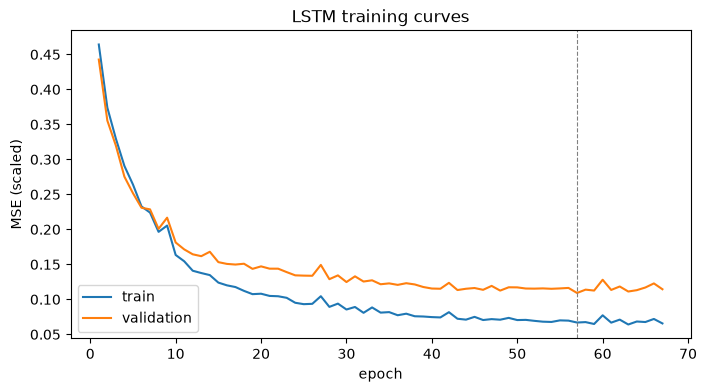

In [20]:
def train_model(Xs, Xd, yt, Xs_val=None, Xd_val=None, y_val=None,
                epochs=100, patience=10, seed=42, lr=1e-3, batch=64):
    """Train with Adam + MSE. With validation data: early stopping, returns best model.
       Without: trains exactly `epochs` epochs (used for the final refit)."""
    torch.manual_seed(seed); np.random.seed(seed)
    m = DayAheadLSTM(Xs.shape[2], Xd.shape[1])
    opt = torch.optim.Adam(m.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    Xs_t, Xd_t, y_t = to_t(Xs), to_t(Xd), to_t(yt)
    hist, best, best_state, wait = [], np.inf, None, 0
    for ep in range(epochs):
        m.train()
        perm = torch.randperm(len(y_t))
        for i in range(0, len(perm), batch):
            b = perm[i:i + batch]
            opt.zero_grad()
            loss = loss_fn(m(Xs_t[b], Xd_t[b]), y_t[b])
            loss.backward(); opt.step()
        m.eval()
        with torch.no_grad():
            tr = loss_fn(m(Xs_t, Xd_t), y_t).item()
            va = loss_fn(m(to_t(Xs_val), to_t(Xd_val)), to_t(y_val)).item() if Xs_val is not None else np.nan
        hist.append((tr, va))
        if Xs_val is not None:
            if va < best - 1e-4:
                best, best_state, wait = va, {k: v.clone() for k, v in m.state_dict().items()}, 0
            else:
                wait += 1
                if wait >= patience:
                    break
    if best_state is not None:
        m.load_state_dict(best_state)
    return m, pd.DataFrame(hist, columns=["train", "validation"])

model, hist = train_model(Xs_tr, Xd_tr, y_tr, Xs_va, Xd_va, y_va)
best_epoch = int(hist["validation"].idxmin()) + 1
print("stopped after", len(hist), "epochs; best epoch =", best_epoch)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(hist.index + 1, hist["train"], label="train"); ax.plot(hist.index + 1, hist["validation"], label="validation")
ax.axvline(best_epoch, color="gray", ls="--", lw=0.8)
ax.set_xlabel("epoch"); ax.set_ylabel("MSE (scaled)"); ax.legend()
ax.set_title("LSTM training curves")
fig.savefig(FIG + "lstm_training_curves.png", dpi=150, bbox_inches="tight")

In [21]:
def lstm_forecast(m, Xs, Xd, idx):
    """Predicted weekly difference (back to GWh) + consumption 7 days earlier = forecast of y(t)."""
    m.eval()
    with torch.no_grad():
        d7_pred = m(to_t(Xs), to_t(Xd)).numpy() * d7_std
    return pd.Series(y.shift(7)[idx].values + d7_pred, index=idx)

lstm_val = lstm_forecast(model, Xs_va, Xd_va, idx_va)

def evaluate(actual, pred, name):
    err = actual - pred
    return pd.Series({"MAE": np.mean(np.abs(err)), "RMSE": np.sqrt(np.mean(err**2)),
                      "MAPE (%)": np.mean(np.abs(err / actual)) * 100}, name=name)

evaluate(y[idx_va], lstm_val, "LSTM").round(2)

MAE         2.68
RMSE        3.41
MAPE (%)    1.87
Name: LSTM, dtype: float64

## Lesson 32 – Several seeds, the final test, and the comparison

In [22]:
SCORES = Path("../results/scores.csv")

def log_scores(table, period):
    """Append a scores table to results/scores.csv (replacing older rows of the same model + period)."""
    new = table.reset_index(names="model").assign(period=period)
    if SCORES.exists():
        old = pd.read_csv(SCORES)
        old = old[~(old["model"].isin(new["model"]) & (old["period"] == period))]
        new = pd.concat([old, new], ignore_index=True)
    new.round(3).to_csv(SCORES, index=False)

In [23]:
seeds = [0, 1, 2, 3, 4]
val_preds, epochs_used = {}, {}
for s in seeds:
    m, h = train_model(Xs_tr, Xd_tr, y_tr, Xs_va, Xd_va, y_va, seed=s)
    epochs_used[s] = int(h["validation"].idxmin()) + 1
    val_preds[s] = lstm_forecast(m, Xs_va, Xd_va, idx_va)
    print(f"seed {s}: best epoch {epochs_used[s]}")

seed_scores = pd.DataFrame([evaluate(y[idx_va], p, f"seed {s}") for s, p in val_preds.items()])
ens_val = pd.concat(val_preds, axis=1).mean(axis=1)
ens_score = evaluate(y[idx_va], ens_val, "LSTM (ensemble of 5 seeds)")
log_scores(pd.DataFrame([ens_score]), "validation 2023")

display(seed_scores.round(2))
print("mean ± std of single seeds: MAE", round(seed_scores["MAE"].mean(), 2), "±", round(seed_scores["MAE"].std(), 2))
ens_score.round(2)

seed 0: best epoch 50
seed 1: best epoch 66
seed 2: best epoch 43
seed 3: best epoch 56
seed 4: best epoch 66


,MAE,RMSE,MAPE (%)
seed 0,2.82,3.55,1.96
seed 1,2.75,3.49,1.91
seed 2,2.84,3.63,1.97
seed 3,2.77,3.49,1.93
seed 4,2.79,3.47,1.93


mean ± std of single seeds: MAE 2.79 ± 0.04


MAE         2.71
RMSE        3.42
MAPE (%)    1.89
Name: LSTM (ensemble of 5 seeds), dtype: float64

In [24]:
Xs_all = np.concatenate([Xs_tr, Xs_va]); Xd_all = np.concatenate([Xd_tr, Xd_va]); y_all = np.concatenate([y_tr, y_va])

test_preds = {}
for s in seeds:
    m, _ = train_model(Xs_all, Xd_all, y_all, epochs=epochs_used[s], seed=s)
    test_preds[s] = lstm_forecast(m, Xs_te, Xd_te, idx_te)

ens_test = pd.concat(test_preds, axis=1).mean(axis=1)
test_single = pd.DataFrame([evaluate(y[idx_te], p, f"seed {s}") for s, p in test_preds.items()])
ens_test_score = evaluate(y[idx_te], ens_test, "LSTM (ensemble of 5 seeds)")
log_scores(pd.DataFrame([ens_test_score]), "test 2024–2025")

print("single seeds on test: MAE", round(test_single["MAE"].mean(), 2), "±", round(test_single["MAE"].std(), 2))
ens_test_score.round(2)

single seeds on test: MAE 3.27 ± 0.04


MAE         3.19
RMSE        4.02
MAPE (%)    2.20
Name: LSTM (ensemble of 5 seeds), dtype: float64

In [25]:
board = pd.read_csv(SCORES)
board = board[board["period"] == "test 2024–2025"].set_index("model")[["MAE", "RMSE", "MAPE (%)"]]
board.sort_values("MAE").round(2)

,MAE,RMSE,MAPE (%)
model,,,
SARIMAX + calendar + Fourier + HDD,2.50,3.26,1.75
SARIMAX + calendar + Fourier,3.17,4.12,2.19
LSTM (ensemble of 5 seeds),3.19,4.03,2.20
SARIMAX + calendar,3.29,4.25,2.28
"SARIMA(1, 0, 0)(0,1,1)7",3.93,5.70,2.77
Holt-Winters (no trend),4.05,5.76,2.85
yearly naive (52 weeks ago),7.56,10.39,5.12
seasonal naive (last week),7.74,10.85,5.24
naive (yesterday),9.59,13.08,6.83


## Summary – Section 6: LSTM (day-ahead)

- Design: target = weekly difference y(t) − y(t−7) (immune to the 2022–23 level shift); LSTM (32 units) over the past 28 days + dense layer over day-t features (HDD, calendar, weekday, Fourier); 6,689 parameters.
- Training: Adam, MSE, early stopping on 2023; 5 seeds, forecasts averaged (ensemble); test models retrained on 2009–2023 for each seed's best epoch count.
- Seed variability small (MAE ± 0.04).

| | Validation 2023 MAE | Test 2024–25 MAE | Test MAPE |
|---|---|---|---|
| LSTM, single seeds | 2.79 ± 0.04 | 3.27 ± 0.04 | – |
| **LSTM, ensemble of 5** | **2.71** | **3.19** | **2.20 %** |
| SARIMAX + calendar + Fourier + HDD (best) | 2.38 | 2.50 | 1.75 % |

- The LSTM beats Holt-Winters (−21 %) and SARIMA (−19 %) but stays 27 % behind SARIMAX with HDD: with ~5,000 days of clearly structured data, the explicit statistical model generalises better.

In [26]:
pd.DataFrame({"LSTM (ensemble)": ens_test}).to_csv("../results/pred_08_lstm.csv", index_label="date")